# Advantage Actor-Critic

A synchronous actor–critic learns from eight CartPole environments. A value head estimates how much return to expect from each state.

In [1]:
from pathlib import Path
import sys

start = Path.cwd()
for parent in (start, *start.parents):
    if (parent / "gallery" / "__init__.py").is_file():
        sys.path.insert(0, str(parent))
        break
else:
    raise RuntimeError("Open this example inside the Machine Learning collection.")

## Actor and critic updates

The shared rollout routine computes generalised advantages with discount 0.99 and trace parameter 0.95. Environment termination and time-limit truncation are handled separately.

In [2]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.distributions import Categorical
from gallery.cartpole import ActorCritic, cart_report, train_on_policy
from gallery.neural import seed_cpu


def update(net, opt, batch):
    states, actions, old_logp, adv, returns = batch
    logits, values = net(states)
    dist = Categorical(logits=logits)
    centred = (adv - adv.mean()) / (adv.std() + 1e-6)
    actor = -(dist.log_prob(actions) * centred).mean()
    critic = nn.functional.mse_loss(values, returns)
    loss = actor + 0.45 * critic - 0.01 * dist.entropy().mean()
    opt.zero_grad()
    loss.backward()
    nn.utils.clip_grad_norm_(net.parameters(), 0.7)
    opt.step()

## Score the trained policy

Each seed uses 76 rollouts of 32 steps in eight environments, totalling 19,456 training transitions.

Uniform-action mean return 29.8; SD 17.0


Seed 17: mean return 17.2, median 17.0, SD 2.5, 500-step fraction 0.0%


Seed 29: mean return 49.4, median 37.5, SD 26.8, 500-step fraction 0.0%


Seed 53: mean return 9.3, median 9.0, SD 0.9, 500-step fraction 0.0%
Across training seeds: mean 25.3, sample SD 21.2


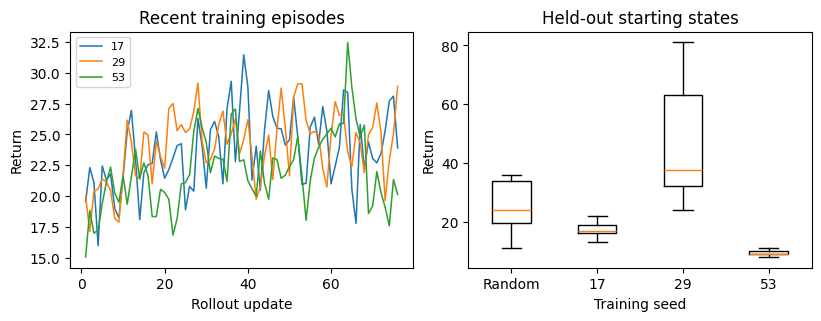

In [3]:
def train(seed):
    return train_on_policy(seed, update)


cart_report(train, "Rollout update")
plt.show()

## Reading the result

Return is capped at 500. The fraction reaching that cap distinguishes consistently long episodes from a high mean produced by a few runs.

## References

[Mnih et al., Asynchronous Methods for Deep Reinforcement Learning (2016), actor–critic background](https://proceedings.mlr.press/v48/mniha16.html)

[Schulman et al., High-Dimensional Continuous Control Using Generalized Advantage Estimation](https://arxiv.org/abs/1506.02438)

[Farama Foundation, Gymnasium CartPole-v1](https://gymnasium.farama.org/environments/classic_control/cart_pole/)

[CartPole rollouts and evaluation](../../../gallery/cartpole.py)